In [28]:
#import libraries 
import os 
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 
import ast
import seaborn as sns

#path for local caching 

file_path="data_jobs.parquet"

#loading data 
if not os.path.exists(file_path):
    dataset=load_dataset('lukebarousse/data_jobs') 
    df=dataset['train'].to_pandas()
    df.to_parquet(file_path)
else:
    df=pd.read_parquet(file_path)

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda skill_list2: ast.literal_eval(skill_list2) if isinstance(skill_list2,str) else skill_list2 )




In [29]:
df_US=df[(df['job_country']== 'United States')].dropna(subset=['salary_year_avg'])

In [30]:
job_titles=df_US['job_title_short'].value_counts().index[:6].tolist()
job_titles 

['Data Scientist',
 'Data Analyst',
 'Data Engineer',
 'Senior Data Scientist',
 'Senior Data Engineer',
 'Senior Data Analyst']

In [31]:
df_US_top6=df_US[df_US['job_title_short'].isin(job_titles)]

In [32]:
job_order=df_US_top6.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index

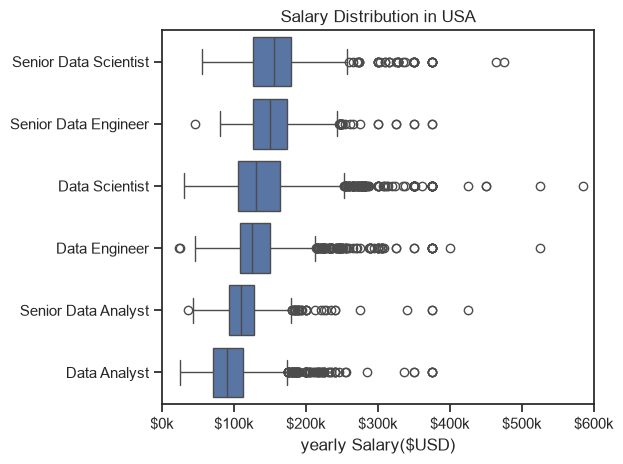

In [33]:
sns.boxplot(data=df_US_top6,x='salary_year_avg',y='job_title_short',order=job_order)
ax=plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,pos:f'${int(x/1000)}k'))
plt.title('Salary Distribution in USA')
plt.xlabel('yearly Salary($USD)')
plt.ylabel('')
plt.xlim(0,600000)
plt.tight_layout()


Investigate Median Salary Vs Skill for Data Analysts

In [34]:
df_DA_US=df[(df['job_title_short']=='Data Analyst')&(df['job_country']=='United States')].copy()
df_DA_US=df_DA_US.dropna(subset=['salary_year_avg'])

In [35]:
df_DA_US=df_DA_US.explode('job_skills')
df_DA_US[['salary_year_avg','job_skills']].head(5)

,salary_year_avg,job_skills
109,89000.0,python
109,89000.0,r
109,89000.0,alteryx
109,89000.0,tableau
180,90250.0,excel


In [36]:
df_DA_top_pay=df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='median',ascending=False)
df_DA_top_pay=df_DA_top_pay.head(10)

In [37]:
df_DA_skills=df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='count',ascending=False)

df_DA_skills=df_DA_skills.head(10).sort_values(by='median',ascending=False)

df_DA_skills


,count,median
job_skills,,
python,1431,97500.00
tableau,1364,92875.00
r,893,92500.00
sql server,286,92500.00
sql,2508,91000.00
sas,926,90000.00
power bi,838,90000.00
powerpoint,462,85000.00
excel,1808,84392.00


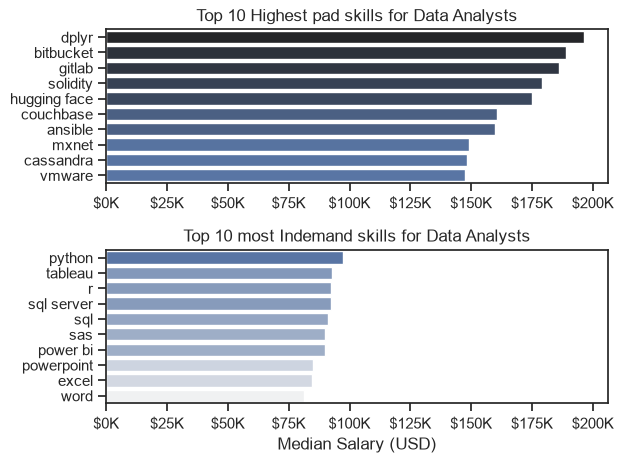

In [ ]:
fig,ax=plt.subplots(2,1)
sns.set_theme(style='ticks')
sns.barplot(data=df_DA_top_pay,x='median',y=df_DA_top_pay.index,ax=ax[0],hue='median',palette='dark:b_r')
ax[0].legend().remove()
# df_DA_skills[::-1].plot(kind='barh',y='median',ax=ax[0],legend=False)
ax[0].set_title('Top 10 Highest pad skills for Data Analysts')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'${int(x/1000)}K'))




sns.barplot(data=df_DA_skills,x='median',y=df_DA_skills.index,ax=ax[1],hue='median',palette='light:b')
ax[1].legend().remove()
# df_DA_skills[::-1].plot(kind='barh',y='median',ax=ax[1],legend=False)
ax[1].set_title('Top 10 most Indemand skills for Data Analysts')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (USD)')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'${int(x/1000)}K'))
ax[1].set_xlim(ax[0].get_xlim())
fig.tight_layout()
